In [1]:
from os.path import basename, exists


def download(url):
    filename = basename(url)
    if not exists(filename):
        from urllib.request import urlretrieve

        local, _ = urlretrieve(url, filename)
        print("Downloaded " + local)


download("https://github.com/AllenDowney/ThinkStats/raw/v3/nb/thinkstats.py")

In [2]:
download("https://github.com/AllenDowney/ThinkStats/raw/v3/nb/relay.py")
download(
    "https://github.com/AllenDowney/ThinkStats/raw/v3/data/Apr25_27thAn_set1.shtml"
)

In [3]:
from relay import read_results

results = read_results()
results.head()

,Place,Div/Tot,Division,Guntime,Nettime,Min/Mile,MPH
0,1,1/362,M2039,30:43,30:42,4:57,12.121212
1,2,2/362,M2039,31:36,31:36,5:06,11.764706
2,3,3/362,M2039,31:42,31:42,5:07,11.726384
3,4,4/362,M2039,32:28,32:27,5:14,11.464968
4,5,5/362,M2039,32:52,32:52,5:18,11.320755


In [4]:
speeds = results['MPH'].values

In [5]:
my_result = results.query("Nettime ==  '42:44'")
my_result

,Place,Div/Tot,Division,Guntime,Nettime,Min/Mile,MPH
96,97,26/256,M4049,42:48,42:44,6:53,8.716707


In [6]:
my_speed = speeds[96]
(speeds<=my_speed).sum()

np.int64(1537)

In [7]:
(speeds <= my_speed).mean() *100

np.float64(94.12124923453766)

In [8]:
def percentile_rank(x, seq):
     """Percentile rank of x.

    x: value
    seq: sequence of values

    returns: percentile rank 0-100
    """
     return (seq <= x).mean() * 100

In [9]:
my_division = results.query("Division == 'M4049' ")
my_division_speeds = my_division['MPH'].values

In [10]:
percentile_rank(my_speed, my_division_speeds)

np.float64(90.234375)

In [11]:
def percentile(p, seq):
    n = len(seq)
    i = (1-p/100)*(n+1)
    return seq[round(i)]

In [12]:
percentile(90, my_division_speeds)

np.float64(8.591885441527447)

In [13]:
next_division = results.query("Division == 'M5059' ")
next_division_speeds = next_division["MPH"].values

percentile(90.2, next_division_speeds)

np.float64(8.017817371937639)

In [14]:
next_division.query("MPH > 8.01").tail(1)

,Place,Div/Tot,Division,Guntime,Nettime,Min/Mile,MPH
222,223,18/171,M5059,46:30,46:25,7:29,8.017817


In [15]:
t = [1,2,2,3,5]

In [16]:
from empiricaldist import Pmf   
pmf = Pmf.from_seq(t)
pmf

,probs
1,0.2
2,0.4
3,0.2
5,0.2


In [17]:
pmf[2]

np.float64(0.4)

In [18]:
cdf = pmf.make_cdf()
cdf

,probs
1,0.2
2,0.6
3,0.8
5,1.0


In [19]:
cdf[2]

np.float64(0.6000000000000001)

In [20]:
cdf(3)

array(0.8)

In [21]:
cdf(4)

array(0.8)

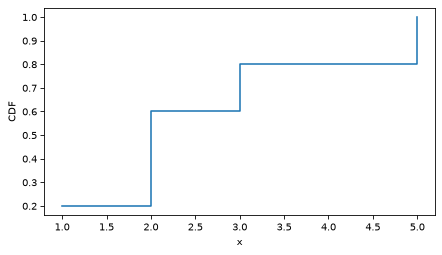

In [22]:
from thinkstats import decorate
cdf.step()
decorate(xlabel = 'x',ylabel = 'CDF')


In [23]:
from empiricaldist import Cdf

cdf_speeds = Cdf.from_seq(speeds)

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

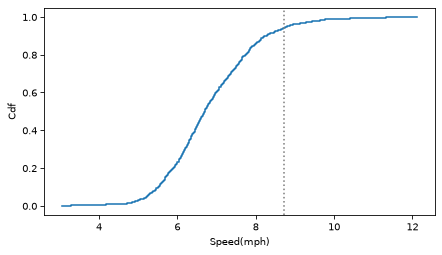

In [25]:
cdf_speeds.step()
plt.axvline(my_speed, ls =":", color = "gray")
decorate(xlabel = "Speed(mph)", ylabel = "Cdf")

In [26]:
cdf_speeds(my_speed) * 100

np.float64(94.12124923453766)

In [27]:
cdf_speeds.inverse(0.5)

array(6.70391061)

In [28]:
try:
    import statadict
except ImportError:
    %pip install statadict

In [29]:
from nsfg import get_nsfg_groups

live, firsts, others = get_nsfg_groups()

/home/axiuc-fedor/think-stats/notebooks/nsfg.py:220: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["totalwgt_lb"] = df.birthwgt_lb + df.birthwgt_oz / 16.0


In [30]:
first_weights = firsts["totalwgt_lb"].dropna()
first_weights.mean()

np.float64(7.201094430437772)

In [31]:
other_weights = others["totalwgt_lb"].dropna()
other_weights.mean()

np.float64(7.325855614973262)

In [32]:
from empiricaldist import Pmf

first_pmf = Pmf.from_seq(first_weights, name = "first")
other_pmf = Pmf.from_seq(other_weights, name = "other")

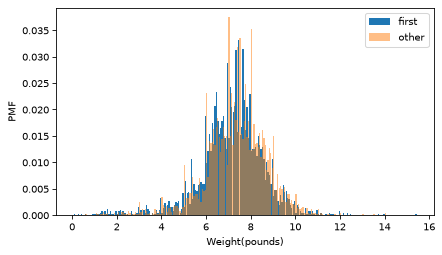

In [33]:
from thinkstats import two_bar_plots

two_bar_plots(first_pmf, other_pmf, width = 0.06)
decorate(xlabel = "Weight(pounds)", ylabel = "PMF")

In [34]:
first_cdf = first_pmf.make_cdf()
other_cdf = other_pmf.make_cdf()

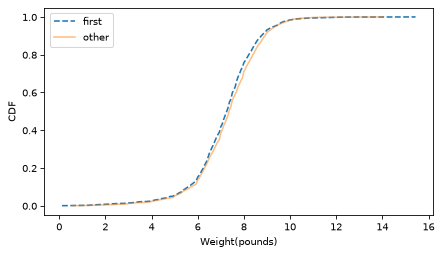

In [35]:
first_cdf.plot(ls='--')
other_cdf.plot(alpha=0.5)
decorate(xlabel = "Weight(pounds)", ylabel = "CDF")

In [36]:
from nsfg import read_stata

dct_file = "2002FemPreg.dct"
dat_file = "2002FemPreg.dat.gz"

preg = read_stata(dct_file, dat_file)

In [37]:
birthwgt_lb = preg["birthwgt_lb"]
birthwgt_oz = preg["birthwgt_oz"]

In [38]:
from empiricaldist import Hist

Hist.from_seq(birthwgt_oz).tail(5)

,freqs
birthwgt_oz,
14.0,475
15.0,378
97.0,1
98.0,1
99.0,46


In [39]:
Hist.from_seq(birthwgt_lb).tail(5)

,freqs
birthwgt_lb,
15.0,1
51.0,1
97.0,1
98.0,1
99.0,57


In [40]:
birthwgt_lb_clean = birthwgt_lb.replace([51,97,98,99], np.nan)
birthwgt_oz_clean = birthwgt_oz.replace([97,98,99], np.nan)

total_weight_clean = birthwgt_lb_clean + birthwgt_oz_clean/16

In [41]:
total_weight_bogus = birthwgt_lb + birthwgt_oz/16

In [42]:
count1, count2 = total_weight_bogus.count(), total_weight_clean.count()
diff = count1-count2

diff, diff / count2 * 100

(np.int64(49), np.float64(0.5421553441026776))

In [43]:
mean1, mean2 = total_weight_bogus.mean(), total_weight_clean.mean()
mean1, mean2

(np.float64(7.319680587652691), np.float64(7.265628457623368))

In [44]:
(mean1 - mean2) / mean2 *100

np.float64(0.74394294099376)

In [45]:
std1, std2 = total_weight_bogus.std(), total_weight_clean.std()
(std1-std2) / std2 * 100

np.float64(48.83274403900607)

In [46]:
def skewness(seq):
    """Compute the skewness of a sequence

    seq: sequence of numbers

    returns: float skewness
    """
    deviations = seq - seq.mean()
    return np.mean(deviations**3) / seq.std(ddof=0)**3

In [47]:
skew1, skew2 = skewness(total_weight_bogus), skewness(total_weight_clean)
skew1, skew2

(np.float64(22.251846195422484), np.float64(-0.5895062687577698))

In [48]:
(skew1-skew2)/skew2

np.float64(-38.74658112171127)

In [49]:
cdf_total_weight_bogus = Cdf.from_seq(total_weight_bogus)
cdf_total_weight_clean = Cdf.from_seq(total_weight_clean)

In [50]:
def median(cdf):
    m = cdf.inverse(0.5)
    return m

In [51]:
median(cdf_total_weight_bogus), median(cdf_total_weight_clean)

(array(7.375), array(7.375))

In [52]:
def iqr(cdf):
    low, high = cdf.inverse([0.25, 0.75])
    return high - low

In [53]:
iqr(cdf_total_weight_bogus), iqr(cdf_total_weight_clean)

(np.float64(1.625), np.float64(1.625))

In [54]:
def quartile_skweness(cdf):
    low, median, high = cdf.inverse([0.25, 0.5, 0.75])
    midpoint = (high+low)/2
    semi_iqr = (high - low)/2

    return (midpoint - median) / semi_iqr 

In [55]:
qskew1 = quartile_skweness(cdf_total_weight_bogus)
qskew2 = quartile_skweness(cdf_total_weight_clean)
qskew1, qskew2

(np.float64(-0.07692307692307693), np.float64(-0.07692307692307693))